# Analisis Telco Customer Churn

| | |
|---|---|
| **Sumber** | https://www.kaggle.com/datasets/blastchar/telco-customer-churn |
| **Ditempatkan di kategori** | Klasifikasi Biner |
| **Jenis klasifikasi sebenarnya** | Biner (Churn = Yes / No) |
| **Status** | ✅ Dataset yang **benar** untuk kategori ini |

## 1. Data Collecting

Dataset diambil dari Kaggle (link di tabel atas).

1. Download dataset dari Kaggle, lalu extract kalau berbentuk ZIP.
2. Taruh file data (`.csv` / `.xlsx`) di **folder yang sama dengan notebook ini**.
3. File data tidak ikut di-push ke GitHub karena sudah masuk `.gitignore`.

In [1]:
# Opsional: download otomatis (perlu `pip install kagglehub` dan login Kaggle)
# import kagglehub
# path = kagglehub.dataset_download("blastchar/telco-customer-churn")
# print(path)

In [2]:
import glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

## 2. Data Loading

In [3]:
DATA_PATH = "WA_Fn-UseC_-Telco-Customer-Churn.csv"   # sesuaikan jika nama file berbeda
df = pd.read_csv(DATA_PATH)
print("Ukuran data (baris, kolom):", df.shape)
df.head()

Ukuran data (baris, kolom): (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

## 3. Identifikasi Jenis Klasifikasi

Cek kolom target `Churn`: berapa kelasnya, dan apakah tiap baris hanya punya satu label.

In [5]:
TARGET = "Churn"
print("Jumlah kelas target:", df[TARGET].nunique())
print(df[TARGET].value_counts())
assert df[TARGET].nunique() == 2
print("\nKesimpulan: target punya 2 kelas dan 1 label per baris -> KLASIFIKASI BINER")

Jumlah kelas target: 2
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Kesimpulan: target punya 2 kelas dan 1 label per baris -> KLASIFIKASI BINER


## 4. Data Cleaning & Transformation

- `customerID` hanya pengenal, bukan fitur, jadi dibuang.
- `TotalCharges` terbaca sebagai teks karena ada nilai kosong berisi spasi, jadi diubah ke angka.
- Duplikat dibuang, target diubah ke 0/1.

In [6]:
df = df.drop(columns=["customerID"])
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

kosong = df.isna().sum()
print("Kolom yang punya nilai kosong:\n", kosong[kosong > 0])
df["TotalCharges"] = df["TotalCharges"].fillna(df["TotalCharges"].median())

print("Duplikat:", df.duplicated().sum())
df = df.drop_duplicates()

df[TARGET] = df[TARGET].map({"No": 0, "Yes": 1})
print("Ukuran setelah cleaning:", df.shape)

Kolom yang punya nilai kosong:
 TotalCharges    11
dtype: int64
Duplikat: 22
Ukuran setelah cleaning: (7021, 20)


## 5. EDA & ExDA

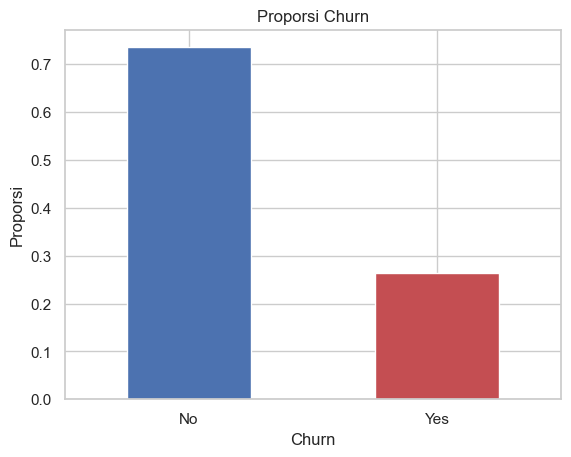

In [7]:
df[TARGET].value_counts(normalize=True).rename({0: "No", 1: "Yes"}).plot(kind="bar", color=["#4c72b0", "#c44e52"])
plt.title("Proporsi Churn"); plt.ylabel("Proporsi"); plt.xticks(rotation=0); plt.show()

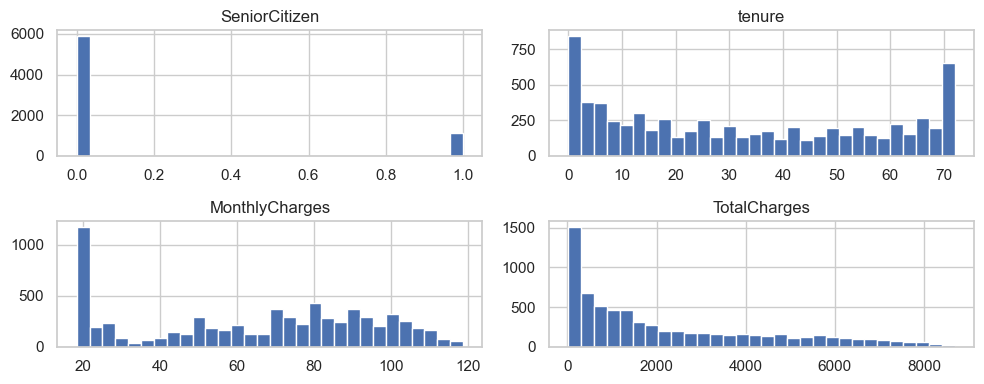

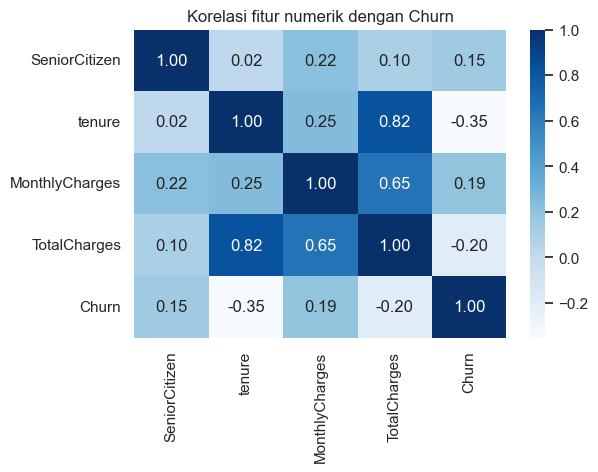

In [8]:
kolom_num = df.select_dtypes(include="number").columns.drop(TARGET).tolist()
df[kolom_num].hist(figsize=(10, 4), bins=30)
plt.tight_layout(); plt.show()

plt.figure(figsize=(6, 4))
sns.heatmap(df[kolom_num + [TARGET]].corr(), annot=True, cmap="Blues", fmt=".2f")
plt.title("Korelasi fitur numerik dengan Churn"); plt.show()

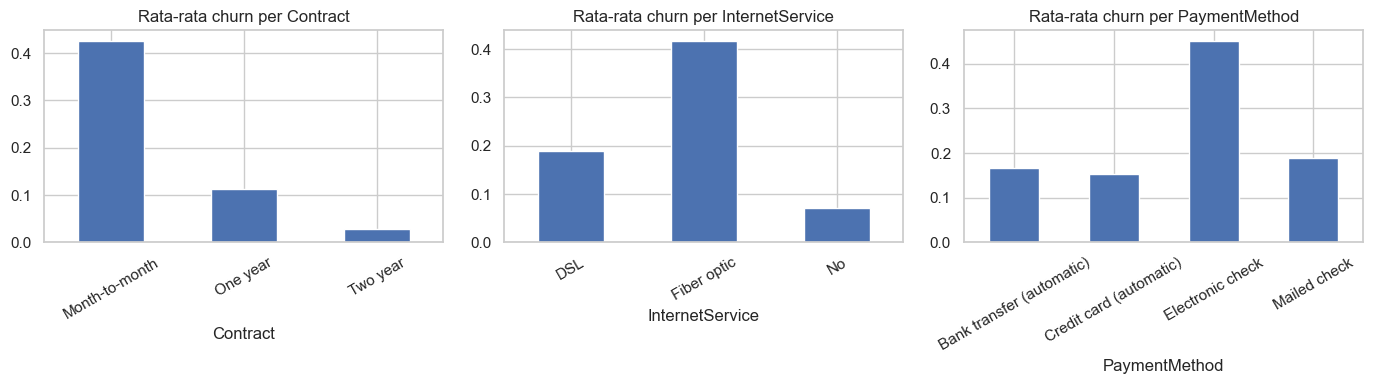

In [9]:
kolom_kat = df.select_dtypes(include="object").columns.tolist()
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, k in zip(ax, ["Contract", "InternetService", "PaymentMethod"]):
    if k in df.columns:
        df.groupby(k)[TARGET].mean().plot(kind="bar", ax=a)
        a.set_title(f"Rata-rata churn per {k}"); a.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

## 6. Data Processing

Fitur kategorikal diubah dengan **One-Hot Encoding**, fitur numerik di-**standardisasi**.
Di sini `preprocessor` baru didefinisikan. Fit-nya dilakukan **setelah data di-split** (bagian 7) supaya tidak terjadi *data leakage*.

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

X = df.drop(columns=[TARGET])
y = df[TARGET]

kolom_kat = X.select_dtypes(include="object").columns.tolist()
kolom_num = X.select_dtypes(exclude="object").columns.tolist()

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), kolom_num),
    ("cat", OneHotEncoder(handle_unknown="ignore"), kolom_kat),
])
print("Fitur numerik    :", kolom_num)
print("Fitur kategorikal:", len(kolom_kat), "kolom")

Fitur numerik    : ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Fitur kategorikal: 15 kolom


## 7. Data Splitting

In [11]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
X_train_p = preprocessor.fit_transform(X_train)   # fit hanya di data latih
X_test_p = preprocessor.transform(X_test)

print("Data latih:", X_train_p.shape, "| Data uji:", X_test_p.shape)
print("Proporsi churn latih/uji:", y_train.mean().round(3), "/", y_test.mean().round(3))

Data latih: (5616, 45) | Data uji: (1405, 45)
Proporsi churn latih/uji: 0.264 / 0.265


## 8. Modelling & Evaluasi

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report, ConfusionMatrixDisplay)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
}

hasil, preds = [], {}
for nama, model in models.items():
    model.fit(X_train_p, y_train)
    pred = model.predict(X_test_p)
    proba = model.predict_proba(X_test_p)[:, 1]
    preds[nama] = pred
    hasil.append({
        "Model": nama,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba),
    })

tabel = pd.DataFrame(hasil).set_index("Model").round(4)
tabel

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.8028,0.6610,0.5242,0.5847,0.8403
Decision Tree,0.7943,0.6203,0.5753,0.5969,0.8296
Gradient Boosting,0.8014,0.6632,0.5081,0.5753,0.8385


Model terbaik berdasarkan F1: Decision Tree 

              precision    recall  f1-score   support

          No       0.85      0.87      0.86      1033
         Yes       0.62      0.58      0.60       372

    accuracy                           0.79      1405
   macro avg       0.74      0.72      0.73      1405
weighted avg       0.79      0.79      0.79      1405



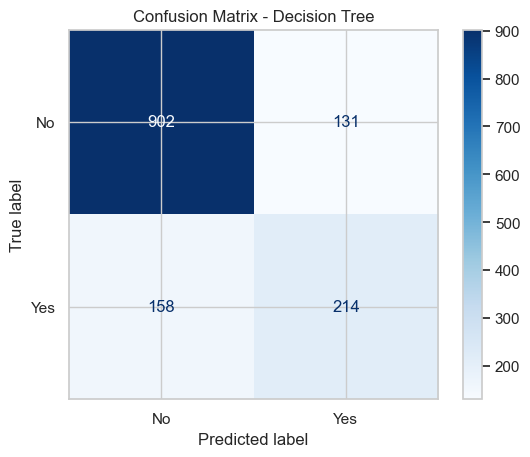

In [13]:
terbaik = tabel["F1"].idxmax()
print("Model terbaik berdasarkan F1:", terbaik, "\n")
print(classification_report(y_test, preds[terbaik], target_names=["No", "Yes"]))
ConfusionMatrixDisplay.from_predictions(y_test, preds[terbaik], display_labels=["No", "Yes"], cmap="Blues")
plt.title(f"Confusion Matrix - {terbaik}"); plt.show()

## 9. Kesimpulan

**Kenapa dataset ini biner.** Kolom target `Churn` hanya punya 2 nilai, yaitu `Yes` (1.869 pelanggan berhenti) dan `No` (5.174 pelanggan bertahan). Setiap pelanggan hanya punya satu label, dan kedua kelas saling lepas karena seorang pelanggan tidak mungkin berhenti dan bertahan sekaligus. Jadi dataset ini termasuk klasifikasi **biner**. Bukan multikelas (kelasnya hanya 2) dan bukan multilabel (hanya ada satu kolom target).

**Data.** Data awal 7.043 baris dan 21 kolom. Kolom `customerID` dibuang karena hanya pengenal. `TotalCharges` terbaca sebagai teks dan setelah diubah ke angka ada 11 nilai kosong, yang diisi dengan median. Ada 22 baris duplikat yang dibuang, sehingga tersisa 7.021 baris dan 20 kolom. Data tidak seimbang: pelanggan yang churn sekitar 26,5%. Karena itu pembagian data memakai `stratify=y`, dan proporsi churn di data latih (0,264) dan data uji (0,265) hampir sama. Setelah One-Hot Encoding, fitur menjadi 45 kolom (4 numerik dan 15 kategorikal yang diubah). Data latih berisi 5.616 baris dan data uji 1.405 baris.

**Temuan EDA.**
- `tenure` punya korelasi negatif terkuat dengan Churn (-0,35): makin lama berlangganan, makin kecil kemungkinan berhenti. `MonthlyCharges` (0,19) dan `SeniorCitizen` (0,15) berkorelasi positif lemah.
- `tenure` dan `TotalCharges` berkorelasi sangat tinggi (0,82), wajar karena total tagihan bertambah seiring lama berlangganan.
- Kontrak sangat berpengaruh: pelanggan Month-to-month churn sekitar 42%, sedangkan One year sekitar 11% dan Two year hanya sekitar 3%.
- Pelanggan Fiber optic lebih sering churn (sekitar 41%) dibanding DSL (sekitar 19%) dan yang tanpa internet (sekitar 7%).
- Pembayaran Electronic check punya tingkat churn tertinggi (sekitar 45%), sedangkan metode lain berkisar 15 sampai 19%.

**Hasil model** (data uji 1.405 baris):

| Model | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| Logistic Regression | **0,8028** | 0,6610 | 0,5242 | 0,5847 | **0,8403** |
| Decision Tree | 0,7943 | 0,6203 | **0,5753** | **0,5969** | 0,8296 |
| Gradient Boosting | 0,8014 | **0,6632** | 0,5081 | 0,5753 | 0,8385 |

**Model terbaik.** Decision Tree dipilih berdasarkan F1 tertinggi (0,5969), karena recall-nya paling tinggi (0,5753) sehingga paling banyak menangkap pelanggan yang benar-benar churn. F1 dipakai, bukan accuracy, karena kelasnya tidak seimbang dan yang paling penting adalah mengenali pelanggan yang akan berhenti. Perlu dicatat, selisih antar model kecil. Logistic Regression unggul di accuracy (0,8028) dan ROC-AUC (0,8403), jadi kalau kriterianya kemampuan memisahkan dua kelas secara umum, Logistic Regression sedikit lebih baik.

**Evaluasi Decision Tree.** Kelas `No` ditebak dengan baik (precision 0,85, recall 0,87, F1 0,86), sedangkan kelas `Yes` lebih sulit (precision 0,62, recall 0,58, F1 0,60). Dari confusion matrix: 902 pelanggan bertahan ditebak benar, 214 pelanggan churn ditebak benar, 131 pelanggan bertahan salah ditebak churn, dan 158 pelanggan churn tidak terdeteksi. Total 289 kesalahan dari 1.405 data uji (sekitar 20,6%).

**Catatan.** Accuracy sekitar 79% tidak sebesar kelihatannya. Model yang selalu menebak "No" sudah mencapai accuracy sekitar 73,5% (1.033 dari 1.405), jadi peningkatannya tidak besar. Recall untuk pelanggan churn juga masih rendah (sekitar 51 sampai 58% di ketiga model), artinya sekitar 4 dari 10 pelanggan yang akan berhenti belum terdeteksi. Perbandingan memakai satu kali pembagian data tanpa cross-validation, jadi selisih kecil antar model belum tentu konsisten. Untuk perbaikan bisa dicoba `class_weight="balanced"`, penyesuaian threshold probabilitas, atau penyetelan hyperparameter.